## MTL Trajet: 05 Single User Purpose Habits (Flag 5)

### Dataset Overview
A constructed single-user case derived from MTL Trajet geometry and purpose/mode context. Work trips share a repeated corridor. All supplied route vertices are retained during resampling; shopping trip _054 uses a cached OSRM road route. Point speeds have within-mode variation, and timestamps integrate the delivered segment distances and speeds. Trip mean speed is distance divided by duration; point_speed_mean_kmh is the unweighted point mean. Conflicting trip dates are reconstructed to remove single-user time overlaps while preserving local departure times and weekdays; source_start_time and calendar_shift_days record the changes.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Assess whether one user has stable individual mobility preferences across repeated trips, and whether those preferences change with trip purpose.

Role: Urban mobility and land-use analyst


Category: Single-user repeated routes, mode-conditioned speed behaviour, and purpose-conditioned routine stability

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Which purposes exhibit repeated route corridors, and which are spatially dispersed?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

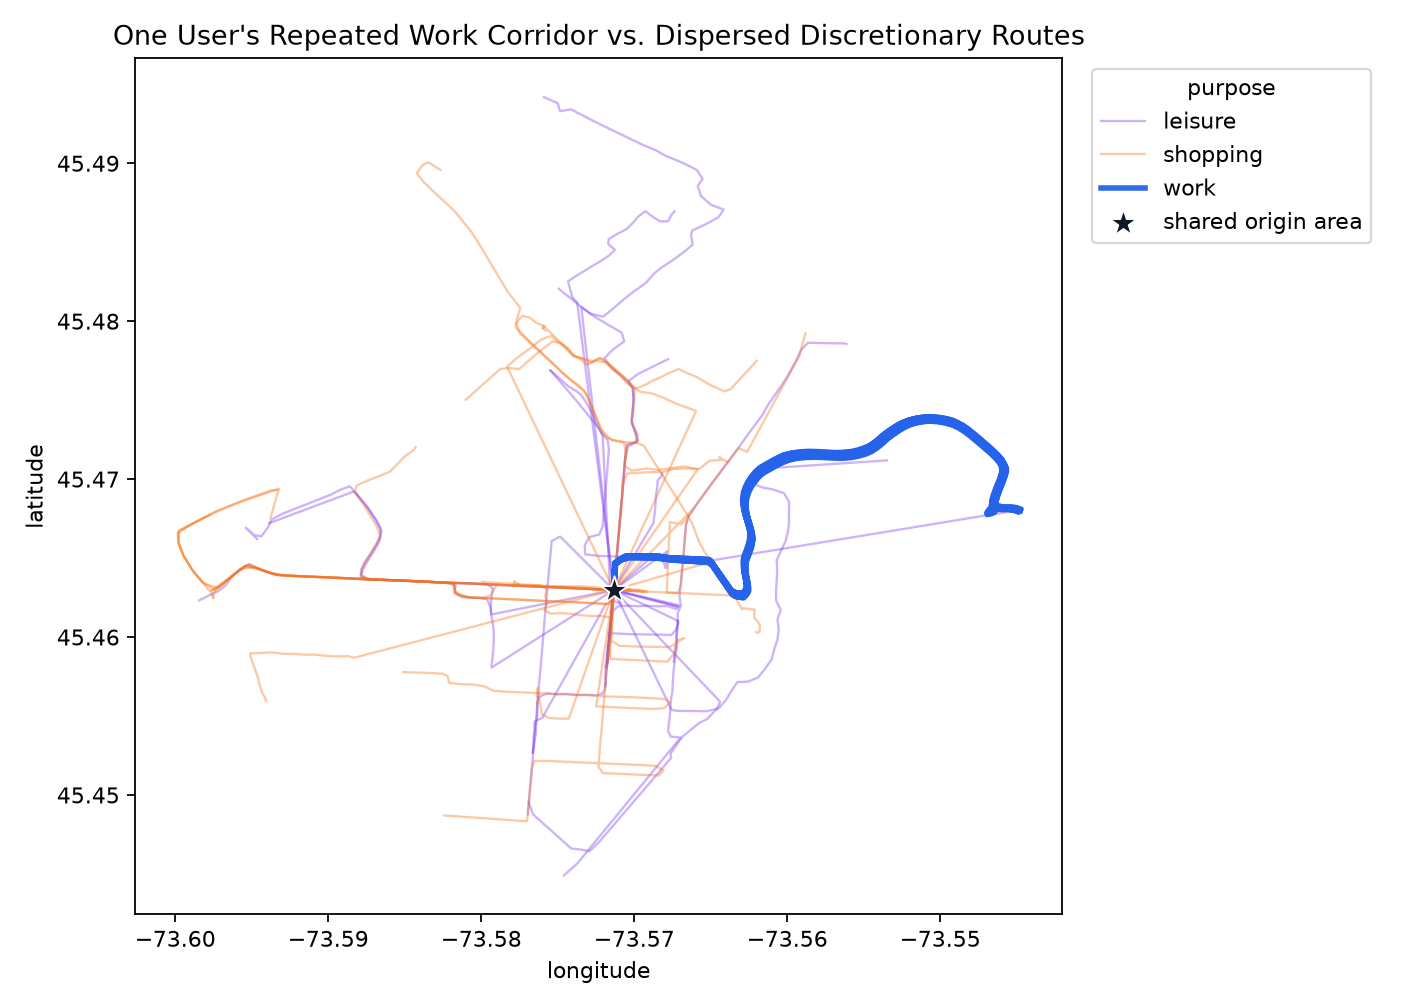

In [ ]:
user_df.groupby(['purpose_group','trajectory_id'])[['longitude','latitude']].agg(['min','max'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/repeated_route_spatial_preference.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "repeated_route_spatial_preference",
  "insight": "This user repeatedly follows the same work-related corridor, with several work trajectories passing through the same road-area sequence; shopping and leisure trajectories are spatially more dispersed.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Repeated Routes and Spatial Preference",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/repeated_route_spatial_preference.png"
  },
  "question": "Which purposes exhibit repeated route corridors, and which are spatially dispersed?",
  "code": "user_df.groupby(['purpose_group','trajectory_id'])[['longitude','latitude']].agg(['min','max'])",
  "insight_type": "group_comparison",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 2**: Within each transport mode, does this user retain comparable typical speed levels and similar acceleration/deceleration rhythms despite different purposes and distances?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

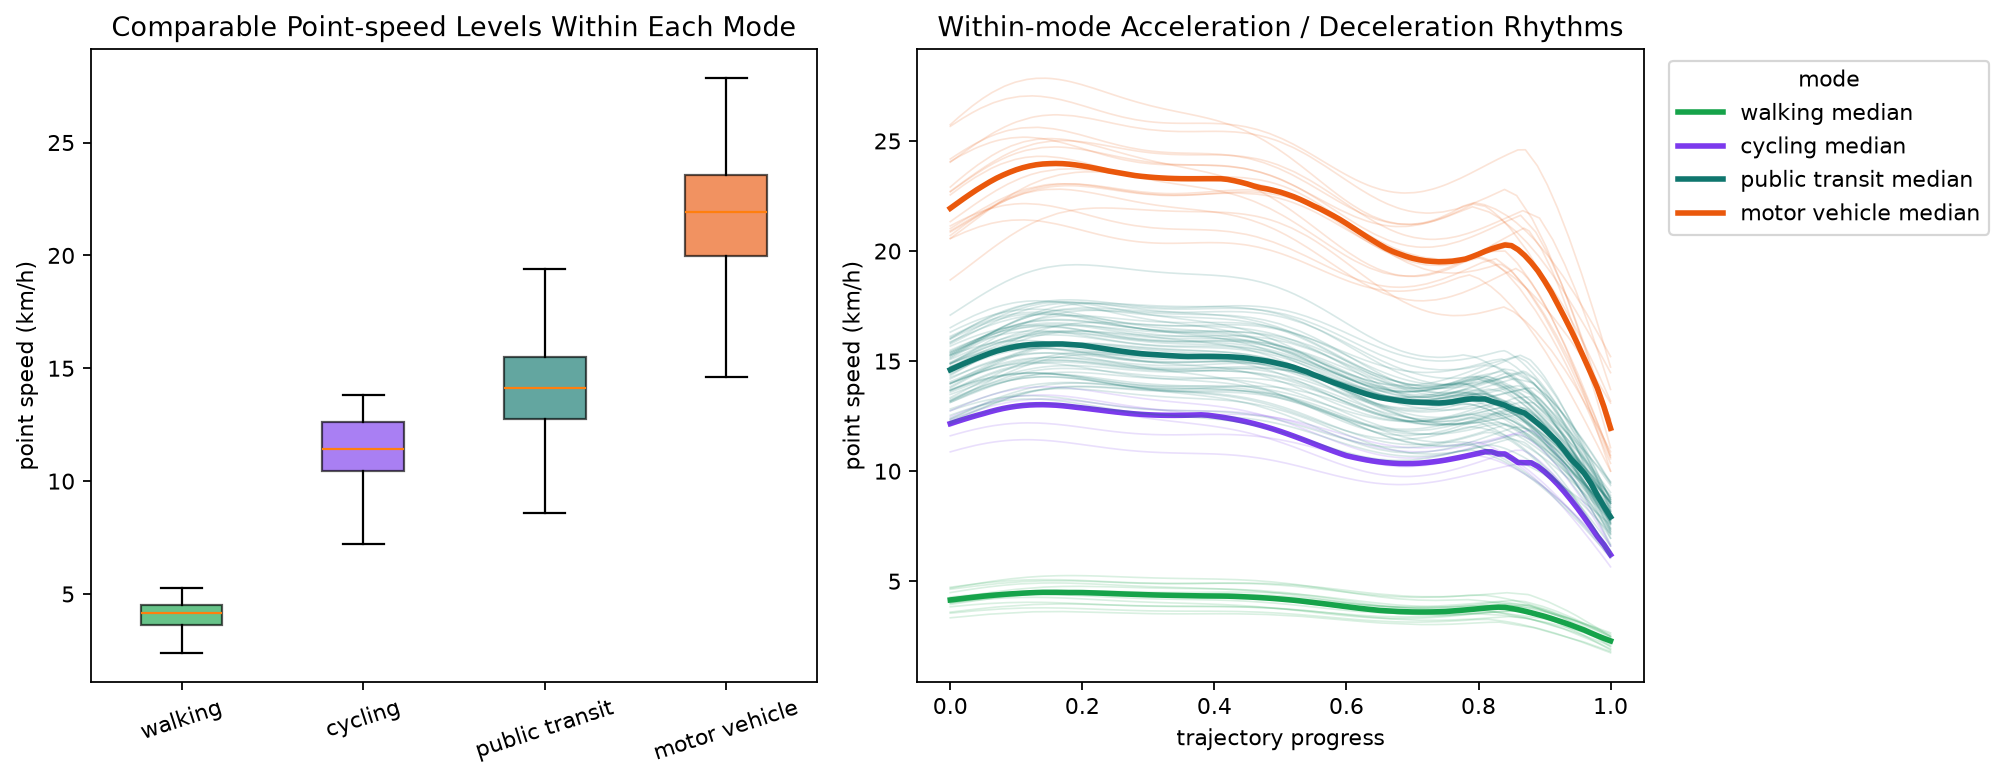

In [ ]:
grid = np.linspace(0,1,101)
fig, axes = plt.subplots(1,3,figsize=(16,4.8),constrained_layout=True)
modes=['walking','cycling','public_transit','motor_vehicle']
colors=['#16a34a','#7c3aed','#0f766e','#ea580c']
axes[0].boxplot([df[df.mode_group.eq(m)].avg_speed_kmh for m in modes],tick_labels=[m.replace('_',' ') for m in modes])
axes[0].set(title='Typical trip speeds within each mode',ylabel='trip mean speed (km/h)');axes[0].tick_params(axis='x',rotation=25)
for mode,color in zip(modes,colors):
    profiles=[]; accelerations=[]
    for _,g in user_df[user_df.mode_group.eq(mode)].groupby('trajectory_id'):
        g=g.sort_values('point_index'); times=pd.to_datetime(g.timestamp,format='mixed'); seconds=(times-times.iloc[0]).dt.total_seconds().to_numpy(); progress=seconds/seconds[-1]
        v=g.speed_kmh.to_numpy(); acceleration=np.diff(v)/3.6/np.diff(seconds)
        profiles.append(np.interp(grid,progress,v));accelerations.append(np.interp(grid,(progress[1:]+progress[:-1])/2,acceleration))
    for ax,data in [(axes[1],profiles),(axes[2],accelerations)]:
        values=np.array(data); ax.fill_between(grid,np.quantile(values,.1,axis=0),np.quantile(values,.9,axis=0),color=color,alpha=.15)
        ax.plot(grid,np.median(values,axis=0),color=color,label=mode.replace('_',' '));ax.grid(alpha=.2)
axes[1].set(title='Within-mode speed rhythms (median, 10–90%)',xlabel='fraction of elapsed trip time',ylabel='speed (km/h)')
axes[2].set(title='Acceleration derived from speed and time',xlabel='fraction of elapsed trip time',ylabel='acceleration (m/s²)')
axes[1].legend(fontsize=8);axes[2].axhline(0,color='gray',lw=.7)
print(df.groupby('mode_group').avg_speed_kmh.agg(['mean','std','min','max']).round(3))
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/mode_speed_consistency.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "individual_mode_speed_consistency",
  "insight": "Even when trip distance and destination differ, this user's trajectories retain comparable typical speed levels and similar acceleration/deceleration rhythms within the same transport mode; the profiles change clearly when the mode changes.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Personal Speed Behaviour by Mode",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/mode_speed_consistency.png"
  },
  "question": "Within each transport mode, does this user retain comparable typical speed levels and similar acceleration/deceleration rhythms despite different purposes and distances?",
  "code": "grid = np.linspace(0,1,101)\nfig, axes = plt.subplots(1,3,figsize=(16,4.8),constrained_layout=True)\nmodes=['walking','cycling','public_transit','motor_vehicle']\ncolors=['#16a34a','#7c3aed','#0f766e','#ea580c']\naxes[0].boxplot([df[df.mode_group.eq(m)].avg_speed_kmh for m in modes],tick_labels=[m.replace('_',' ') for m in modes])\naxes[0].set(title='Typical trip speeds within each mode',ylabel='trip mean speed (km/h)');axes[0].tick_params(axis='x',rotation=25)\nfor mode,color in zip(modes,colors):\n    profiles=[]; accelerations=[]\n    for _,g in user_df[user_df.mode_group.eq(mode)].groupby('trajectory_id'):\n        g=g.sort_values('point_index'); times=pd.to_datetime(g.timestamp,format='mixed'); seconds=(times-times.iloc[0]).dt.total_seconds().to_numpy(); progress=seconds/seconds[-1]\n        v=g.speed_kmh.to_numpy(); acceleration=np.diff(v)/3.6/np.diff(seconds)\n        profiles.append(np.interp(grid,progress,v));accelerations.append(np.interp(grid,(progress[1:]+progress[:-1])/2,acceleration))\n    for ax,data in [(axes[1],profiles),(axes[2],accelerations)]:\n        values=np.array(data); ax.fill_between(grid,np.quantile(values,.1,axis=0),np.quantile(values,.9,axis=0),color=color,alpha=.15)\n        ax.plot(grid,np.median(values,axis=0),color=color,label=mode.replace('_',' '));ax.grid(alpha=.2)\naxes[1].set(title='Within-mode speed rhythms (median, 10–90%)',xlabel='fraction of elapsed trip time',ylabel='speed (km/h)')\naxes[2].set(title='Acceleration derived from speed and time',xlabel='fraction of elapsed trip time',ylabel='acceleration (m/s²)')\naxes[1].legend(fontsize=8);axes[2].axhline(0,color='gray',lw=.7)\nprint(df.groupby('mode_group').avg_speed_kmh.agg(['mean','std','min','max']).round(3))\nplt.show()",
  "insight_type": "factor_relationship",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "gps_position",
    "trajectory_timestamp",
    "point_speed",
    "trajectory_id"
  ]
}

### **Question 3**: Which purposes have stable time/mode routines, and which vary more in time, mode, and trip length?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

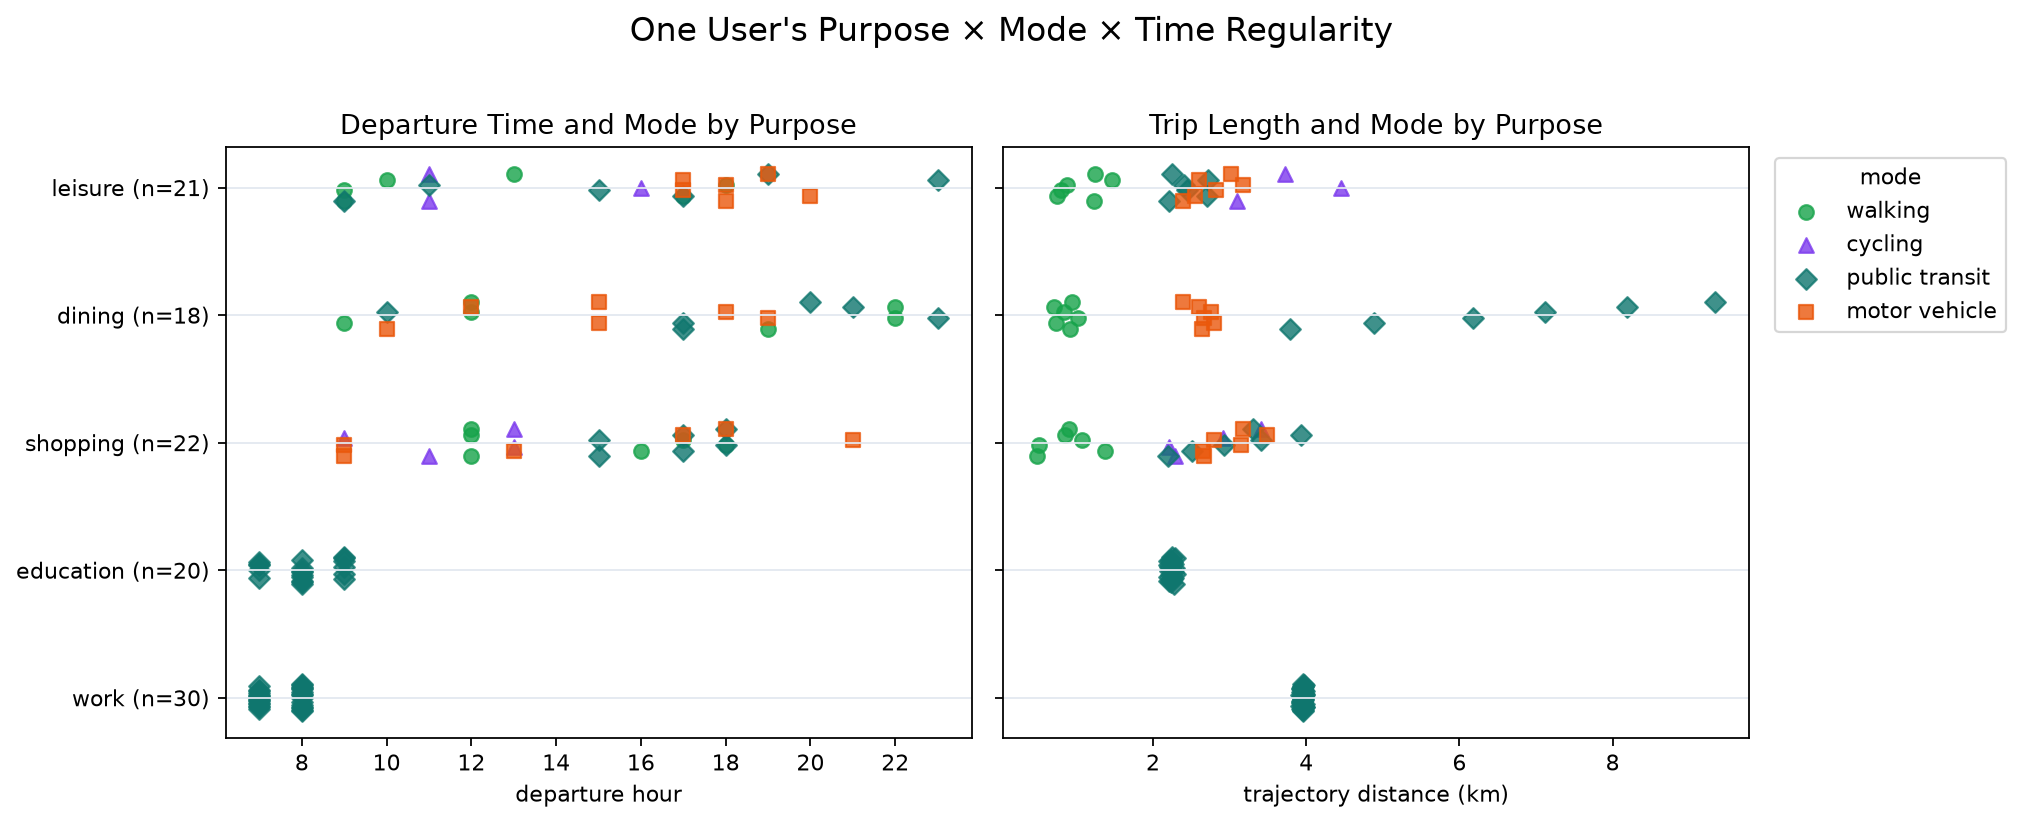

In [ ]:
df.groupby('purpose_group').agg(start_hour_nunique=('start_hour','nunique'), mode_nunique=('mode_group','nunique'), distance_std=('distance_km','std'))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/purpose_mode_time_stability.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "purpose_mode_time_stability",
  "insight": "The user's routine work and education trips have more stable departure times and transport modes, while shopping, dining, and leisure trips vary more in departure time, mode, and trajectory length.",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Purpose × Mode × Time Stability",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/purpose_mode_time_stability.png"
  },
  "question": "Which purposes have stable time/mode routines, and which vary more in time, mode, and trip length?",
  "code": "df.groupby('purpose_group').agg(start_hour_nunique=('start_hour','nunique'), mode_nunique=('mode_group','nunique'), distance_std=('distance_km','std'))",
  "insight_type": "group_comparison",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "gps_position",
    "trajectory_timestamp",
    "transport_mode",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 5)

This single-user history contains a repeated work commute corridor and mode-consistent point-speed profiles. Work and education are routine-like in time and mode, whereas shopping, dining, and leisure cover more varied times, modes, destinations, and distances.